# TP3 — Prise en main de Spark SQL
## SparkSession, DataFrames, SQL et sources de données
**Anwar Ezzirani · G4 · 5IIR · Data Science & AI**  
Module : Écosystème Big Data 2 · Enseignante : Pr Fadwa FATHI  
Date : 9 novembre 2026

Compte rendu et notebook exécuté. Toutes les questions des parties 0 à 6 sont traitées.
Le travail initial des parties 0 à 2 est conservé et enrichi d'explications ; les parties
3 à 6 complètent la réalisation. Les résultats et captures proviennent d'une exécution
réelle sous Spark 4.0.0 dans Docker. Les deux erreurs attendues sont interceptées.

## Partie 0 — Préparation des données
La cellule crée les trois fichiers de l'énoncé : `people.json`, `people.txt` et
`employes.csv`. Les huit employés sont repris à l'identique. Le dossier `data_tp1`
est conservé pour correspondre aux chemins de l'énoncé, bien qu'il s'agisse du TP3.
Les chemins sont relatifs au dossier du notebook pour faciliter la reproduction.

In [1]:
import os, sys, json, logging, platform
from pathlib import Path
from datetime import datetime
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
ART = ROOT / "artifacts"
CAP = ART / "captures"
for folder in (ART, CAP):
    folder.mkdir(parents=True, exist_ok=True)
RESULTATS = {}
# Compatibilité avec les images Jupyter qui exposent Spark via SPARK_HOME.
spark_home = os.environ.get("SPARK_HOME")
if spark_home:
    spark_python = Path(spark_home) / "python"
    for chemin in [spark_python, *spark_python.glob("lib/py4j-*-src.zip")]:
        if str(chemin) not in sys.path:
            sys.path.insert(0, str(chemin))
    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
for nom_logger in ("SQLQueryContextLogger", "DataFrameQueryContextLogger"):
    logging.getLogger(nom_logger).setLevel(logging.CRITICAL)
from pyspark.sql import SparkSession, Row
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType
)


os.makedirs("data_tp1", exist_ok=True)

with open("data_tp1/people.json", "w", encoding="utf-8") as f:
    f.write('{"name":"Michael"}\n')
    f.write('{"name":"Andy","age":30}\n')
    f.write('{"name":"Justin","age":19}\n')

with open("data_tp1/people.txt", "w", encoding="utf-8") as f:
    f.write("Michael, 29\nAndy, 30\nJustin, 19\n")

employes = [
    (1, "Sara", "Informatique", "Casablanca", 14000, 28),
    (2, "Youssef", "Informatique", "Rabat", 16500, 35),
    (3, "Imane", "Finance", "Casablanca", 12000, 41),
    (4, "Omar", "Finance", "Tanger", 9500, 26),
    (5, "Salma", "RH", "Rabat", 8800, 30),
    (6, "Hamza", "Informatique", "Marrakech", 11000, 24),
    (7, "Khadija", "RH", "Casablanca", 10200, 38),
    (8, "Anas", "Finance", "Rabat", 13500, 45),
]

colonnes = ["id", "nom", "departement", "ville", "salaire", "age"]

with open("data_tp1/employes.csv", "w", encoding="utf-8") as f:
    f.write(",".join(colonnes) + "\n")
    for e in employes:
        f.write(",".join(str(x) for x in e) + "\n")

print("Fichiers créés :", os.listdir("data_tp1"))

Fichiers créés : ['employes.csv', 'people.json', 'people.txt']


## Partie 1 — SparkSession
### Q1.1 — Création de la session
`SparkSession` est le point d'entrée de l'API DataFrame et SQL. `local[*]` utilise
les processeurs disponibles ; `spark.sql.shuffle.partitions = 4` configure le nombre
initial de partitions des shuffles SQL. L'optimisation adaptative peut ensuite les fusionner.
Le nom `TP1 - Spark SQL` est celui demandé par l'énoncé du TP3.

In [2]:
spark = (
    SparkSession.builder
    .appName("TP1 - Spark SQL")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.ui.port", "4040")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("OFF")

### Q1.2 — Vérification de la configuration
Le conteneur est limité à quatre processeurs ; `local[*]` exploite les ressources
qu'il voit. Les valeurs sont affichées depuis la session réellement créée.

In [3]:
print("Version :", spark.version)
print("Application :", sc.appName)
print("Master :", sc.master)
print("Partitions SQL :", spark.conf.get("spark.sql.shuffle.partitions"))
print("Parallélisme disponible :", sc.defaultParallelism)
print("Python :", platform.python_version())
print("Java :", sc._jvm.java.lang.System.getProperty("java.version"))
print("Exécution UTC :", datetime.now().astimezone().isoformat())
print("Spark UI :", sc.uiWebUrl)
assert spark.version == "4.0.0"
assert sc.master == "local[*]"
assert spark.conf.get("spark.sql.shuffle.partitions") == "4"

Version : 4.0.0
Application : TP1 - Spark SQL
Master : local[*]


Partitions SQL : 4
Parallélisme disponible : 4
Python : 3.13.5
Java : 17.0.16
Exécution UTC : 2026-11-09T12:42:21.687204+00:00
Spark UI : http://a7270c71cb91:4040


### Q1.3 — Mode ANSI et conversions invalides
En mode ANSI, une conversion invalide provoque une exception au lieu de retourner
silencieusement une valeur nulle. `try_cast` permet explicitement de remplacer une
conversion impossible par `NULL`. Le bloc `try/except` démontre l'erreur sans interrompre le TP.

In [4]:
print("Mode ANSI :", spark.conf.get("spark.sql.ansi.enabled"))
assert spark.conf.get("spark.sql.ansi.enabled") == "true"
erreur_cast = False
try:
    spark.sql("SELECT CAST('abc' AS INT) AS resultat").show()
except Exception as exc:
    erreur_cast = True
    print("Erreur attendue :", type(exc).__name__)
    print("CAST('abc' AS INT) est invalide en mode ANSI.")
assert erreur_cast
try_cast_df = spark.sql("SELECT try_cast('abc' AS INT) AS resultat")
try_cast_df.show()
assert try_cast_df.first()["resultat"] is None

Mode ANSI : true


Erreur attendue : NumberFormatException
CAST('abc' AS INT) est invalide en mode ANSI.


+--------+
|resultat|
+--------+
|    NULL|
+--------+



## Partie 2 — DataFrame à partir d'une séquence
### Q2.1 — Création et schéma inféré
Le DataFrame contient huit lignes et six colonnes. Spark infère les entiers Python
comme `long` (`bigint`), et les champs du schéma inféré sont nullables.
Un DataFrame est distribué et immuable : les transformations créent de nouveaux DataFrames.

In [5]:
df_emp = spark.createDataFrame(employes, colonnes)

df_emp.show()
df_emp.printSchema()

+---+-------+------------+----------+-------+---+
| id|    nom| departement|     ville|salaire|age|
+---+-------+------------+----------+-------+---+
|  1|   Sara|Informatique|Casablanca|  14000| 28|
|  2|Youssef|Informatique|     Rabat|  16500| 35|
|  3|  Imane|     Finance|Casablanca|  12000| 41|
|  4|   Omar|     Finance|    Tanger|   9500| 26|
|  5|  Salma|          RH|     Rabat|   8800| 30|
|  6|  Hamza|Informatique| Marrakech|  11000| 24|
|  7|Khadija|          RH|Casablanca|  10200| 38|
|  8|   Anas|     Finance|     Rabat|  13500| 45|
+---+-------+------------+----------+-------+---+

root
 |-- id: long (nullable = true)
 |-- nom: string (nullable = true)
 |-- departement: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- salaire: long (nullable = true)
 |-- age: long (nullable = true)



### Q2.2 — Colonnes, types, effectif et statistiques
La moyenne attendue des salaires est de 11 937,50 MAD, avec un minimum de 8 800
et un maximum de 16 500. `describe` produit notamment l'effectif, la moyenne et
l'écart-type d'échantillon. `count()` et `show()` déclenchent l'exécution du calcul.

In [6]:
print("Colonnes :", df_emp.columns)
print("Types :", df_emp.dtypes)
print("Nombre d'employés :", df_emp.count())

df_emp.describe("salaire").show()
assert df_emp.count() == 8
stats_salaire = df_emp.agg(F.sum("salaire").alias("total"), F.avg("salaire").alias("moyenne"),
                         F.min("salaire").alias("minimum"), F.max("salaire").alias("maximum")).first()
RESULTATS["statistiques_salaires"] = stats_salaire.asDict()
assert stats_salaire["total"] == 95500 and stats_salaire["moyenne"] == 11937.5

Colonnes : ['id', 'nom', 'departement', 'ville', 'salaire', 'age']
Types : [('id', 'bigint'), ('nom', 'string'), ('departement', 'string'), ('ville', 'string'), ('salaire', 'bigint'), ('age', 'bigint')]


Nombre d'employés : 8


+-------+-----------------+
|summary|          salaire|
+-------+-----------------+
|  count|                8|
|   mean|          11937.5|
| stddev|2596.666819487739|
|    min|             8800|
|    max|            16500|
+-------+-----------------+



### Q2.3 — Schéma explicite
Les colonnes `id`, `salaire` et `age` deviennent des `integer` (32 bits), au lieu de
`long` (64 bits). `id` devient non nullable ; les autres champs restent nullables.
Le contenu est identique, mais le schéma est désormais contrôlé et documenté.
La contrainte de non-nullité ne signifie pas que Spark crée une clé primaire unique.

In [7]:
schema_emp = StructType([
    StructField("id", IntegerType(), nullable=False),
    StructField("nom", StringType(), nullable=True),
    StructField("departement", StringType(), nullable=True),
    StructField("ville", StringType(), nullable=True),
    StructField("salaire", IntegerType(), nullable=True),
    StructField("age", IntegerType(), nullable=True)
])

df_emp2 = spark.createDataFrame(employes, schema=schema_emp)

df_emp2.show()
df_emp2.printSchema()
assert not df_emp2.schema["id"].nullable
assert isinstance(df_emp2.schema["id"].dataType, IntegerType)
assert sorted(tuple(r) for r in df_emp.collect()) == sorted(tuple(r) for r in df_emp2.collect())
print("Contenus identiques ; types numériques et nullabilité de id différents.")

+---+-------+------------+----------+-------+---+
| id|    nom| departement|     ville|salaire|age|
+---+-------+------------+----------+-------+---+
|  1|   Sara|Informatique|Casablanca|  14000| 28|
|  2|Youssef|Informatique|     Rabat|  16500| 35|
|  3|  Imane|     Finance|Casablanca|  12000| 41|
|  4|   Omar|     Finance|    Tanger|   9500| 26|
|  5|  Salma|          RH|     Rabat|   8800| 30|
|  6|  Hamza|Informatique| Marrakech|  11000| 24|
|  7|Khadija|          RH|Casablanca|  10200| 38|
|  8|   Anas|     Finance|     Rabat|  13500| 45|
+---+-------+------------+----------+-------+---+

root
 |-- id: integer (nullable = false)
 |-- nom: string (nullable = true)
 |-- departement: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- salaire: integer (nullable = true)
 |-- age: integer (nullable = true)



Contenus identiques ; types numériques et nullabilité de id différents.


## Partie 3 — DataFrames à partir de sources de données
### Q3.1 — Lecture du JSON
Michael n'a pas de champ `age` dans le JSON : sa valeur est donc `NULL`.
Les âges présents sont inférés comme `long` (`bigint`). Le fichier JSON contient
un objet par ligne ; il ne s'agit pas d'un tableau JSON multiligne.

In [8]:
df_people_json = spark.read.json("data_tp1/people.json")
df_people_json.show()
df_people_json.printSchema()
print("Type de age :", df_people_json.schema["age"].dataType.simpleString())
assert df_people_json.filter(F.col("name") == "Michael").first()["age"] is None
assert df_people_json.schema["age"].dataType.simpleString() == "bigint"

+----+-------+
| age|   name|
+----+-------+
|NULL|Michael|
|  30|   Andy|
|  19| Justin|
+----+-------+

root
 |-- age: long (nullable = true)
 |-- name: string (nullable = true)

Type de age : bigint


### Q3.2 — Lecture du CSV et inférence
Avec `header` seulement, toutes les colonnes sont des chaînes. Avec `inferSchema`,
Spark examine les données et reconnaît ici `id`, `salaire` et `age` comme `integer`.
L'inférence d'un CSV n'est pas identique à l'inférence d'une liste Python.

In [9]:
df_csv_a = spark.read.option("header", True).csv("data_tp1/employes.csv")
df_csv_b = (spark.read.option("header", True).option("inferSchema", True)
            .csv("data_tp1/employes.csv"))
print("CSV avec header seulement :")
df_csv_a.printSchema()
print("CSV avec header et inferSchema :")
df_csv_b.printSchema()
df_csv_b.show()
assert all(t == "string" for _, t in df_csv_a.dtypes)
assert dict(df_csv_b.dtypes)["salaire"] == "int"

CSV avec header seulement :
root
 |-- id: string (nullable = true)
 |-- nom: string (nullable = true)
 |-- departement: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- salaire: string (nullable = true)
 |-- age: string (nullable = true)

CSV avec header et inferSchema :
root
 |-- id: integer (nullable = true)
 |-- nom: string (nullable = true)
 |-- departement: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- salaire: integer (nullable = true)
 |-- age: integer (nullable = true)

+---+-------+------------+----------+-------+---+
| id|    nom| departement|     ville|salaire|age|
+---+-------+------------+----------+-------+---+
|  1|   Sara|Informatique|Casablanca|  14000| 28|
|  2|Youssef|Informatique|     Rabat|  16500| 35|
|  3|  Imane|     Finance|Casablanca|  12000| 41|
|  4|   Omar|     Finance|    Tanger|   9500| 26|
|  5|  Salma|          RH|     Rabat|   8800| 30|
|  6|  Hamza|Informatique| Marrakech|  11000| 24|
|  7|Khadija|          RH|Ca

### Q3.3 — Lecteur générique et comparaison
`format("csv").load(...)` utilise le même lecteur que `.csv(...)`.
On vérifie le schéma et les différences dans les deux sens : une seule différence
vide ne suffit pas à prouver l'égalité de deux collections. `exceptAll` prend aussi
en compte les doublons et compare les colonnes par leur position.

In [10]:
df_csv_generique = (spark.read.format("csv").option("header", True)
                    .option("inferSchema", True).load("data_tp1/employes.csv"))
ecart_ab = df_csv_generique.exceptAll(df_csv_b).count()
ecart_ba = df_csv_b.exceptAll(df_csv_generique).count()
print("Schémas identiques :", df_csv_generique.schema == df_csv_b.schema)
print("Différences générique - csv :", ecart_ab)
print("Différences csv - générique :", ecart_ba)
assert df_csv_generique.schema == df_csv_b.schema and ecart_ab == ecart_ba == 0

Schémas identiques : True
Différences générique - csv : 0
Différences csv - générique : 0


### Q3.4 — Pourquoi éviter `inferSchema` sur de gros volumes ?
L'inférence nécessite un parcours supplémentaire des données pour déterminer les types,
ce qui augmente les lectures et le temps de démarrage. Elle rend aussi le contrat de
données dépendant du contenu observé. Avec un échantillonnage, des valeurs rares peuvent
ne pas être représentées. On recommande un `StructType` explicite, versionné et réutilisable.
La lecture ci-dessous illustre cette alternative avec le schéma de Q2.3.

In [11]:
df_csv_schema = (spark.read.option("header", True).schema(schema_emp)
                 .csv("data_tp1/employes.csv"))
df_csv_schema.printSchema()
print("Nombre de lignes avec schéma fourni :", df_csv_schema.count())
assert df_csv_schema.count() == 8

root
 |-- id: integer (nullable = true)
 |-- nom: string (nullable = true)
 |-- departement: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- salaire: integer (nullable = true)
 |-- age: integer (nullable = true)

Nombre de lignes avec schéma fourni : 8


## Partie 4 — Opérations sur DataFrame
### Q4.1 — Projection et salaire annuel
`select` conserve les colonnes demandées. Une expression de colonne calcule le salaire
annuel ; `alias` donne son nom au résultat. Exemple : Sara, 14 000 × 12 = 168 000 MAD.
Le DataFrame `df_emp` d'origine conserve ses six colonnes.

In [12]:
df_emp.select("nom", "salaire").show()
df_annuel = df_emp.select("nom", "salaire", (F.col("salaire") * 12).alias("salaire_annuel"))
df_annuel.show()
assert df_annuel.filter(F.col("nom") == "Sara").first()["salaire_annuel"] == 168000
assert len(df_emp.columns) == 6

+-------+-------+
|    nom|salaire|
+-------+-------+
|   Sara|  14000|
|Youssef|  16500|
|  Imane|  12000|
|   Omar|   9500|
|  Salma|   8800|
|  Hamza|  11000|
|Khadija|  10200|
|   Anas|  13500|
+-------+-------+

+-------+-------+--------------+
|    nom|salaire|salaire_annuel|
+-------+-------+--------------+
|   Sara|  14000|        168000|
|Youssef|  16500|        198000|
|  Imane|  12000|        144000|
|   Omar|   9500|        114000|
|  Salma|   8800|        105600|
|  Hamza|  11000|        132000|
|Khadija|  10200|        122400|
|   Anas|  13500|        162000|
+-------+-------+--------------+



### Q4.2 — Filtrage avec deux conditions
Les employés Informatique ayant un salaire strictement supérieur à 12 000 sont
Sara (14 000) et Youssef (16 500). Les conditions de colonnes utilisent `&` et doivent
être parenthésées ; le mot-clé Python `and` ne convient pas à ces expressions distribuées.

In [13]:
df_info = df_emp.filter((F.col("departement") == "Informatique") & (F.col("salaire") > 12000))
df_info.orderBy("id").show()
assert sorted(r.nom for r in df_info.collect()) == ["Sara", "Youssef"]

+---+-------+------------+----------+-------+---+
| id|    nom| departement|     ville|salaire|age|
+---+-------+------------+----------+-------+---+
|  1|   Sara|Informatique|Casablanca|  14000| 28|
|  2|Youssef|Informatique|     Rabat|  16500| 35|
+---+-------+------------+----------+-------+---+



### Q4.3 — Colonne conditionnelle `profil`
Les conditions sont évaluées dans l'ordre : Junior si âge < 30 ; Confirmé si
30 ≤ âge < 40 ; Senior si âge ≥ 40. Ainsi Salma, âgée de 30 ans, est Confirmé.
Les catégories attendues comptent 3 Juniors, 3 Confirmés et 2 Seniors.

In [14]:
df_profils = df_emp.withColumn("profil", F.when(F.col("age") < 30, "Junior")
                              .when(F.col("age") < 40, "Confirmé").otherwise("Senior"))
df_profils.orderBy("id").show()
profils = {r["profil"]: r["count"] for r in df_profils.groupBy("profil").count().collect()}
print("Effectifs des profils :", profils)
assert profils == {"Junior": 3, "Confirmé": 3, "Senior": 2}
RESULTATS["profils"] = profils

+---+-------+------------+----------+-------+---+--------+
| id|    nom| departement|     ville|salaire|age|  profil|
+---+-------+------------+----------+-------+---+--------+
|  1|   Sara|Informatique|Casablanca|  14000| 28|  Junior|
|  2|Youssef|Informatique|     Rabat|  16500| 35|Confirmé|
|  3|  Imane|     Finance|Casablanca|  12000| 41|  Senior|
|  4|   Omar|     Finance|    Tanger|   9500| 26|  Junior|
|  5|  Salma|          RH|     Rabat|   8800| 30|Confirmé|
|  6|  Hamza|Informatique| Marrakech|  11000| 24|  Junior|
|  7|Khadija|          RH|Casablanca|  10200| 38|Confirmé|
|  8|   Anas|     Finance|     Rabat|  13500| 45|  Senior|
+---+-------+------------+----------+-------+---+--------+



Effectifs des profils : {'Junior': 3, 'Confirmé': 3, 'Senior': 2}


### Q4.4 — Agrégation par département
Une seule agrégation calcule l'effectif, la moyenne arrondie à zéro décimale et
le maximum. `round` arrondit la moyenne affichée ; elle n'est pas tronquée.
Les moyennes attendues sont : Finance 11 667, Informatique 13 833, RH 9 500 MAD.

In [15]:
agg_dept = df_emp.groupBy("departement").agg(
    F.count("*").alias("nb_employes"),
    F.round(F.avg("salaire"), 0).alias("salaire_moyen"),
    F.max("salaire").alias("salaire_max"))
agg_dept.orderBy("departement").show()
RESULTATS["departements"] = [r.asDict() for r in agg_dept.orderBy("departement").collect()]

+------------+-----------+-------------+-----------+
| departement|nb_employes|salaire_moyen|salaire_max|
+------------+-----------+-------------+-----------+
|     Finance|          3|      11667.0|      13500|
|Informatique|          3|      13833.0|      16500|
|          RH|          2|       9500.0|      10200|
+------------+-----------+-------------+-----------+



### Q4.5 — Trois salaires les plus élevés
Le tri décroissant précède la limite. Le classement attendu est Youssef (16 500),
Sara (14 000), puis Anas (13 500). Un second critère `id` rend le tri déterministe
en cas d'égalité de salaire.

In [16]:
top3 = df_emp.orderBy(F.desc("salaire"), F.asc("id")).limit(3)
top3.show()
assert [r.nom for r in top3.collect()] == ["Youssef", "Sara", "Anas"]
RESULTATS["top3"] = [r.asDict() for r in top3.collect()]

+---+-------+------------+----------+-------+---+
| id|    nom| departement|     ville|salaire|age|
+---+-------+------------+----------+-------+---+
|  2|Youssef|Informatique|     Rabat|  16500| 35|
|  1|   Sara|Informatique|Casablanca|  14000| 28|
|  8|   Anas|     Finance|     Rabat|  13500| 45|
+---+-------+------------+----------+-------+---+



## Partie 5 — Requêtes SQL
### Q5.1 — Vue temporaire, `GROUP BY` et `HAVING`
La vue locale expose `df_emp` au SQL dans cette session. `HAVING` filtre les groupes
après calcul de leur moyenne, tandis que `WHERE` filtre les lignes avant agrégation.
Informatique et Finance dépassent 10 000 MAD ; RH, dont la moyenne est 9 500, est exclu.

In [17]:
df_emp.createOrReplaceTempView("employes")
sql_moyennes = spark.sql("""
    SELECT departement, AVG(salaire) AS salaire_moyen
    FROM employes
    GROUP BY departement
    HAVING AVG(salaire) > 10000
    ORDER BY salaire_moyen DESC
""")
sql_moyennes.show()
assert [r.departement for r in sql_moyennes.collect()] == ["Informatique", "Finance"]
RESULTATS["departements_plus_10000"] = [r.asDict() for r in sql_moyennes.collect()]

+------------+------------------+
| departement|     salaire_moyen|
+------------+------------------+
|Informatique|13833.333333333334|
|     Finance|11666.666666666666|
+------------+------------------+



### Q5.2 — Vue globale et nouvelle session
Une vue globale se référence avec le préfixe `global_temp` et est partagée entre
les sessions de la même application Spark. `newSession()` crée un état SQL distinct,
mais partage le SparkContext. La vue locale `employes` reste invisible dans cette
nouvelle session. Une vue globale n'est pas une table durable entre applications.

In [18]:
df_emp.createOrReplaceGlobalTempView("emp_global")
spark2 = spark.newSession()
spark2.sql("SELECT * FROM global_temp.emp_global ORDER BY id").show()
print("Même SparkContext :", spark2.sparkContext is sc)
print("Vue employes visible dans la première session :", spark.catalog.tableExists("employes"))
print("Vue employes visible dans la nouvelle session :", spark2.catalog.tableExists("employes"))
assert spark2.sql("SELECT * FROM global_temp.emp_global").count() == 8
assert not spark2.catalog.tableExists("employes")
erreur_vue = False
try:
    spark2.sql("SELECT * FROM employes").show()
except Exception as exc:
    erreur_vue = True
    print("Erreur attendue pour la vue locale :", type(exc).__name__)
    print("La vue employes n'existe pas dans la nouvelle session.")
assert erreur_vue

+---+-------+------------+----------+-------+---+
| id|    nom| departement|     ville|salaire|age|
+---+-------+------------+----------+-------+---+
|  1|   Sara|Informatique|Casablanca|  14000| 28|
|  2|Youssef|Informatique|     Rabat|  16500| 35|
|  3|  Imane|     Finance|Casablanca|  12000| 41|
|  4|   Omar|     Finance|    Tanger|   9500| 26|
|  5|  Salma|          RH|     Rabat|   8800| 30|
|  6|  Hamza|Informatique| Marrakech|  11000| 24|
|  7|Khadija|          RH|Casablanca|  10200| 38|
|  8|   Anas|     Finance|     Rabat|  13500| 45|
+---+-------+------------+----------+-------+---+

Même SparkContext : True
Vue employes visible dans la première session : True
Vue employes visible dans la nouvelle session : False


Erreur attendue pour la vue locale : AnalysisException
La vue employes n'existe pas dans la nouvelle session.


### Q5.3 — Requête directe sur un fichier JSON
Le SQL référence directement `json.` suivi du chemin entre accents graves.
Andy (30 ans) est le seul résultat : Justin a 19 ans et Michael a un âge `NULL`
dans ce JSON. La condition `NULL > 20` ne vaut pas vrai ; Michael est donc exclu.
Aucun DataFrame source ni aucune vue intermédiaire ne sont créés pour cette requête.

In [19]:
chemin_json = (ROOT / "data_tp1/people.json").as_posix()
sql_fichier = spark.sql(f"SELECT * FROM json.`{chemin_json}` WHERE age > 20")
sql_fichier.show()
assert [r.name for r in sql_fichier.collect()] == ["Andy"]

+---+----+
|age|name|
+---+----+
| 30|Andy|
+---+----+



### Q5.4 — Même agrégation en SQL et comparaison des plans
La requête ci-dessous reprend exactement les expressions et alias de Q4.4.
L'API DataFrame et SQL passent par le même analyseur et optimiseur Catalyst :
les plans présentent des opérateurs équivalents, notamment les agrégations partielles
et finales ainsi que l'échange par département. Les identifiants internes et l'état
d'Adaptive Query Execution peuvent varier ; on ne compare pas les chaînes caractère par caractère.

In [20]:
sql_agg_dept = spark.sql("""
    SELECT departement,
           COUNT(*) AS nb_employes,
           ROUND(AVG(salaire), 0) AS salaire_moyen,
           MAX(salaire) AS salaire_max
    FROM employes
    GROUP BY departement
""")
sql_agg_dept.orderBy("departement").show()
print("PLAN PHYSIQUE — API DATAFRAME")
agg_dept.explain()
print("\nPLAN PHYSIQUE — SQL")
sql_agg_dept.explain()
ecart_df_sql = agg_dept.exceptAll(sql_agg_dept).count()
ecart_sql_df = sql_agg_dept.exceptAll(agg_dept).count()
print("Différences DataFrame - SQL :", ecart_df_sql)
print("Différences SQL - DataFrame :", ecart_sql_df)
assert ecart_df_sql == ecart_sql_df == 0
plan_df = agg_dept._jdf.queryExecution().executedPlan().toString()
plan_sql = sql_agg_dept._jdf.queryExecution().executedPlan().toString()
for plan in (plan_df, plan_sql):
    assert "HashAggregate" in plan and "Exchange" in plan
(ART / "plan_dataframe.txt").write_text(plan_df, encoding="utf-8")
(ART / "plan_sql.txt").write_text(plan_sql, encoding="utf-8")
RESULTATS["equivalence_dataframe_sql"] = True

+------------+-----------+-------------+-----------+
| departement|nb_employes|salaire_moyen|salaire_max|
+------------+-----------+-------------+-----------+
|     Finance|          3|      11667.0|      13500|
|Informatique|          3|      13833.0|      16500|
|          RH|          2|       9500.0|      10200|
+------------+-----------+-------------+-----------+

PLAN PHYSIQUE — API DATAFRAME
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[departement#9], functions=[count(1), avg(salaire#11L), max(salaire#11L)])
   +- Exchange hashpartitioning(departement#9, 4), ENSURE_REQUIREMENTS, [plan_id=1293]
      +- HashAggregate(keys=[departement#9], functions=[partial_count(1), partial_avg(salaire#11L), partial_max(salaire#11L)])
         +- Project [departement#9, salaire#11L]
            +- Scan ExistingRDD[id#7L,nom#8,departement#9,ville#10,salaire#11L,age#12L]



PLAN PHYSIQUE — SQL
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregat

Différences DataFrame - SQL : 0
Différences SQL - DataFrame : 0


## Partie 6 — Conversions entre RDD et DataFrame
### Q6.1 — RDD d'objets `Row` et schéma inféré
Le découpage produit un nom et un âge converti en entier Python. Spark infère
`name` comme `string` et `age` comme `long`. Attention : Michael a ici 29 ans,
car `people.txt` renseigne son âge, contrairement au fichier JSON.

In [21]:
rdd_lignes = sc.textFile("data_tp1/people.txt", 2)
rdd_rows = (rdd_lignes.map(lambda ligne: ligne.split(","))
            .map(lambda p: Row(name=p[0].strip(), age=int(p[1].strip()))))
df_people = spark.createDataFrame(rdd_rows)
df_people.orderBy("name").show()
df_people.printSchema()
assert df_people.schema["age"].dataType.simpleString() == "bigint"
assert df_people.filter(F.col("name") == "Michael").first().age == 29

+-------+---+
|   name|age|
+-------+---+
|   Andy| 30|
| Justin| 19|
|Michael| 29|
+-------+---+

root
 |-- name: string (nullable = true)
 |-- age: long (nullable = true)



### Q6.2 — RDD de tuples et schéma explicite
La conversion utilise cette fois un RDD de tuples et un schéma fourni : `name`
est non nullable et `age` est de type `integer`. Les valeurs restent identiques à
Q6.1. Le schéma explicite évite de demander à Spark de deviner les types.

In [22]:
rdd_tuples = (rdd_lignes.map(lambda ligne: ligne.split(","))
              .map(lambda p: (p[0].strip(), int(p[1].strip()))))
schema_people = StructType([StructField("name", StringType(), False),
                            StructField("age", IntegerType(), True)])
df_people_exp = spark.createDataFrame(rdd_tuples, schema_people)
df_people_exp.orderBy("name").show()
df_people_exp.printSchema()
assert not df_people_exp.schema["name"].nullable
assert df_people_exp.schema["age"].dataType.simpleString() == "int"
assert sorted(tuple(r) for r in df_people.collect()) == sorted(tuple(r) for r in df_people_exp.collect())

+-------+---+
|   name|age|
+-------+---+
|   Andy| 30|
| Justin| 19|
|Michael| 29|
+-------+---+

root
 |-- name: string (nullable = false)
 |-- age: integer (nullable = true)



### Q6.3 — DataFrame vers RDD et accès aux champs
L'attribut `.rdd` fournit un RDD dont les éléments sont des objets `pyspark.sql.Row`.
On accède au champ `name` par `ligne.name`, `ligne["name"]` ou `ligne[0]`.
`asDict()` permet aussi d'obtenir un dictionnaire Python. `take(2)` est une action
qui ramène seulement deux éléments sur le driver.

In [23]:
rdd_people = df_people.rdd
deux = rdd_people.take(2)
print("Deux éléments :", deux)
print("Type du premier élément :", type(deux[0]))
print("Accès attribut :", deux[0].name)
print("Accès par nom de champ :", deux[0]["name"])
print("Accès par position :", deux[0][0])
print("Dictionnaire :", deux[0].asDict())
assert isinstance(deux[0], Row)
assert deux[0].name == deux[0]["name"] == deux[0][0]
RESULTATS["people_txt"] = [r.asDict() for r in df_people.orderBy("name").collect()]

Deux éléments : [Row(name='Michael', age=29), Row(name='Andy', age=30)]
Type du premier élément : <class 'pyspark.sql.types.Row'>
Accès attribut : Michael
Accès par nom de champ : Michael
Accès par position : Michael
Dictionnaire : {'name': 'Michael', 'age': 29}


## Vérification des résultats et synthèse
Une référence Python indépendante vérifie les statistiques par département et le
classement des salaires. Les assertions précédentes contrôlent également les lectures,
les profils, la portée des vues et les conversions. Aucun résultat métier n'est ressaisi
dans les sorties. La moyenne globale ne se calcule pas en faisant la moyenne simple
des moyennes des départements, car leurs effectifs diffèrent.

In [24]:
from collections import defaultdict
from statistics import mean, stdev
ref = defaultdict(list)
for ident, nom, departement, ville, salaire, age in employes:
    ref[departement].append(salaire)
attendus = [{"departement": dep, "nb_employes": len(valeurs),
             "salaire_moyen": float(round(mean(valeurs))), "salaire_max": max(valeurs)}
            for dep, valeurs in sorted(ref.items())]
assert RESULTATS["departements"] == attendus
assert stats_salaire.moyenne == mean(e[4] for e in employes)
assert [r.nom for r in top3.collect()] == [e[1] for e in sorted(employes, key=lambda e: (-e[4], e[0]))[:3]]
RESULTATS["validation"] = "Toutes les assertions ont réussi, y compris la référence Python indépendante."
RESULTATS["environnement"] = {"spark": spark.version, "python": platform.python_version(),
                              "master": sc.master, "shuffle_partitions": spark.conf.get("spark.sql.shuffle.partitions")}
(ART / "resultats.json").write_text(json.dumps(RESULTATS, ensure_ascii=False, indent=2), encoding="utf-8")
print("VALIDATION : toutes les vérifications ont réussi.")
print("Employés : 8 | Total des salaires : 95 500 MAD | Moyenne : 11 937,50 MAD")
print("Meilleurs salaires : Youssef, Sara, Anas")
print("Deux erreurs attendues et interceptées : CAST invalide ; vue locale inaccessible.")
print("Questions couvertes : 1.1–1.3, 2.1–2.3, 3.1–3.4, 4.1–4.5, 5.1–5.4, 6.1–6.3.")

VALIDATION : toutes les vérifications ont réussi.
Employés : 8 | Total des salaires : 95 500 MAD | Moyenne : 11 937,50 MAD
Meilleurs salaires : Youssef, Sara, Anas
Deux erreurs attendues et interceptées : CAST invalide ; vue locale inaccessible.
Questions couvertes : 1.1–1.3, 2.1–2.3, 3.1–3.4, 4.1–4.5, 5.1–5.4, 6.1–6.3.


## Captures de l'exécution réelle
Les captures suivantes documentent l'application Spark SQL de ce notebook :
l'onglet SQL, le détail d'une requête agrégée avec son plan et les stages exécutés.
Elles sont intégrées aux sorties du notebook et à son export PDF.

**Spark UI — requêtes SQL et DataFrame**

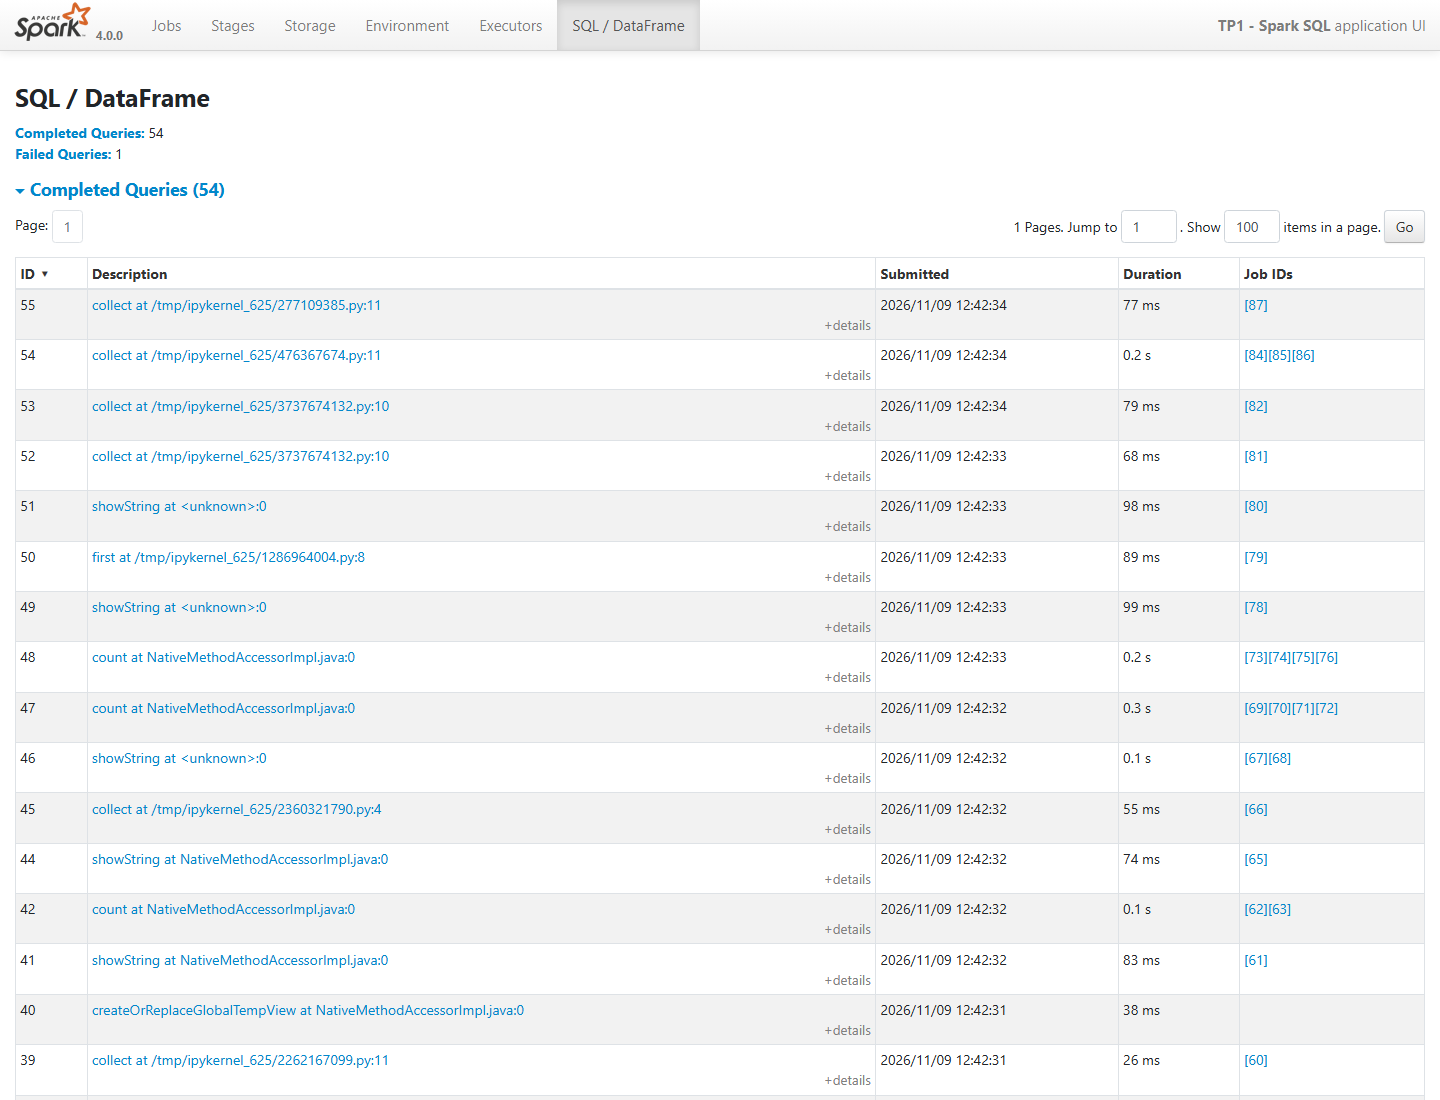

**Spark UI — détail d'une agrégation et plan d'exécution**

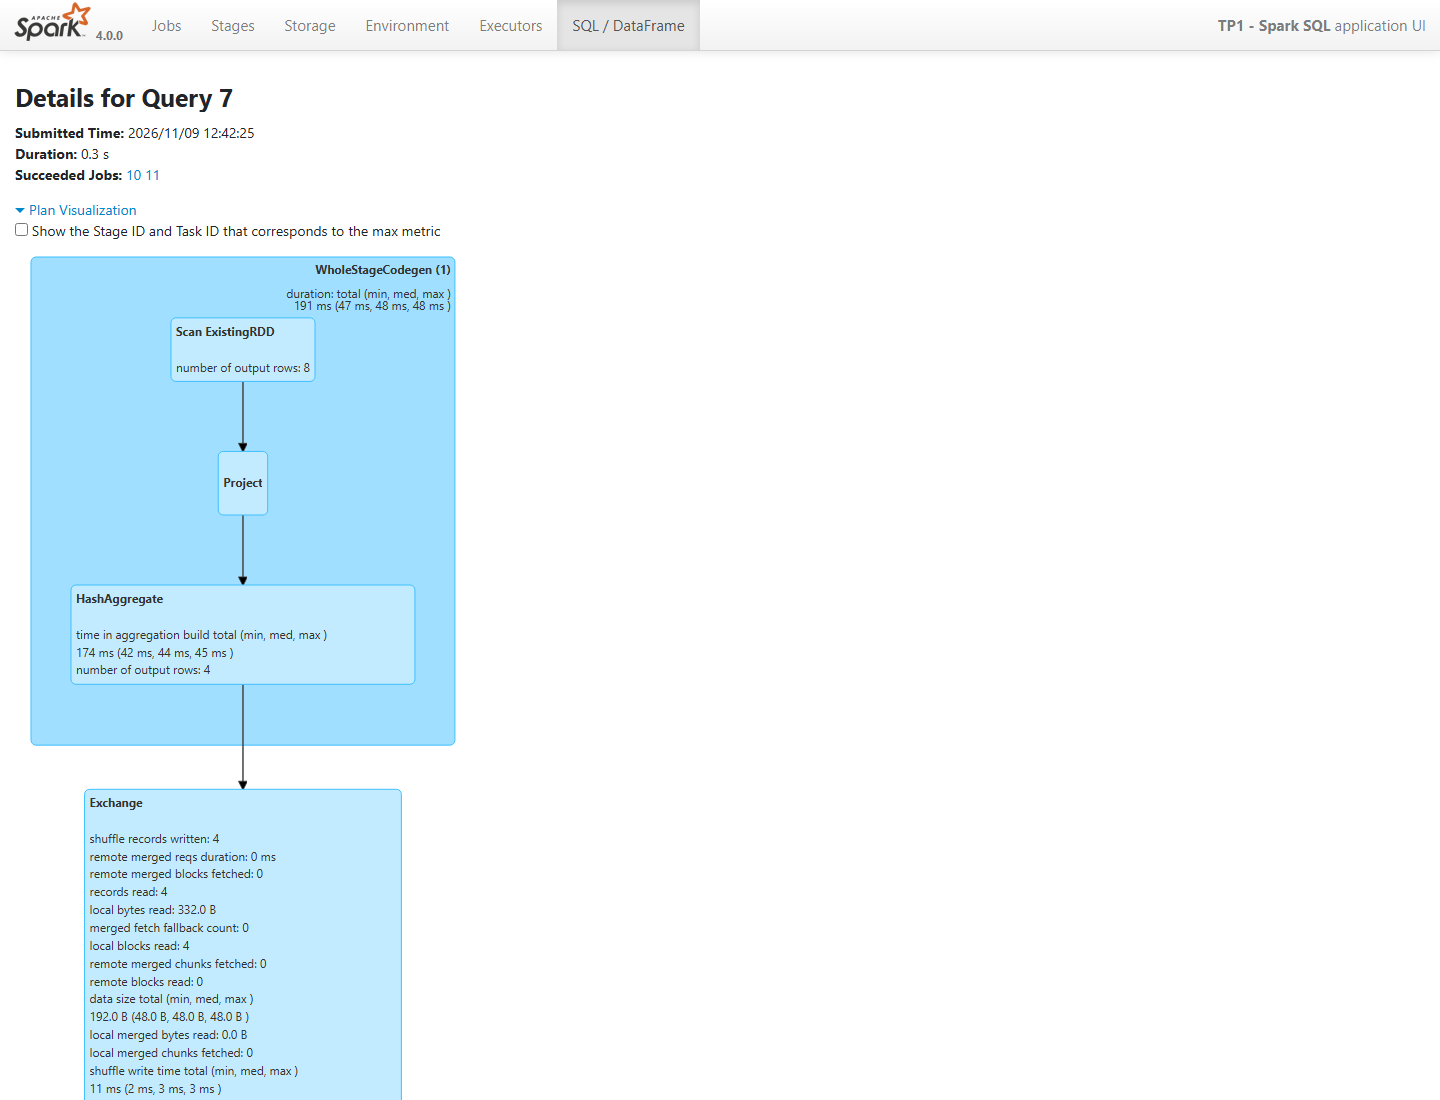

**Spark UI — stages de cette exécution**

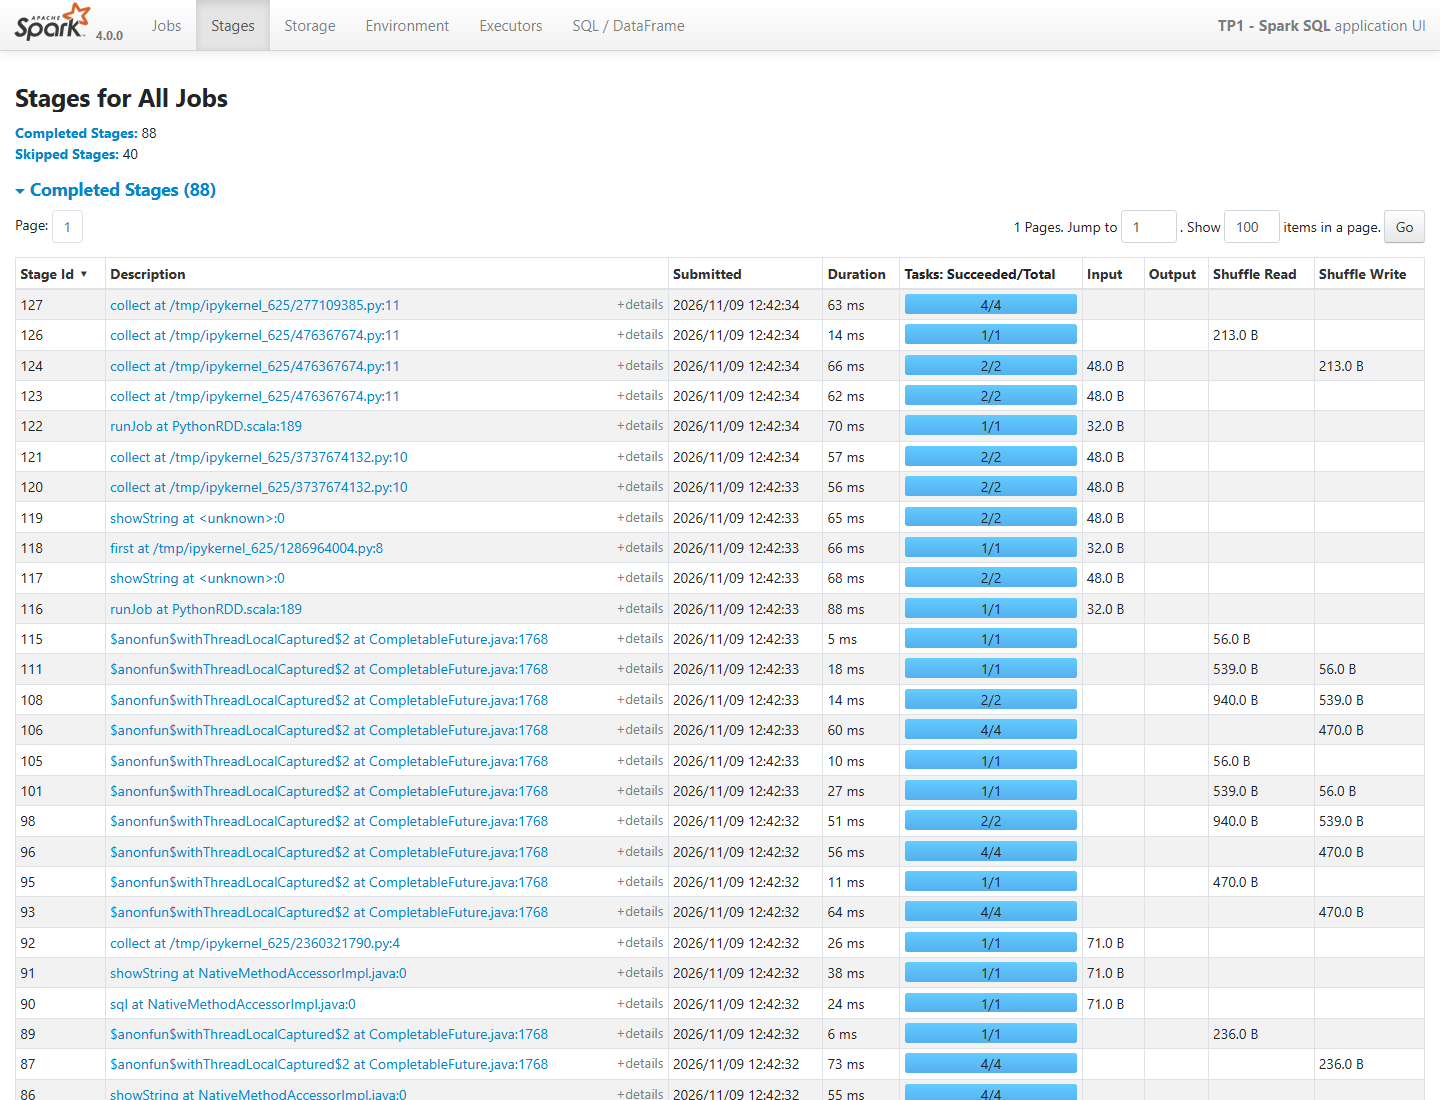

In [25]:
# Pendant la production du livrable, un navigateur capture Spark UI sur l'hôte.
if os.environ.get("TP3_CAPTURE") == "1":
    import time, requests
    (ART / "capture_request.json").write_text(json.dumps({"application": sc.applicationId}), encoding="utf-8")
    deadline = time.monotonic() + 120
    while not (ART / "capture_done.json").exists():
        if time.monotonic() > deadline:
            raise TimeoutError("Les captures Spark UI n'ont pas été reçues.")
        time.sleep(1)
for fichier, legende in [("sql.png", "Spark UI — requêtes SQL et DataFrame"),
                          ("sql_plan.png", "Spark UI — détail d'une agrégation et plan d'exécution"),
                          ("stages.png", "Spark UI — stages de cette exécution")]:
    chemin = CAP / fichier
    if chemin.exists():
        display(Markdown("**" + legende + "**"))
        display(Image(filename=str(chemin), width=1100))
    else:
        print("Capture archivée dans les sorties du notebook de livraison :", fichier)

## Références et reproduction
- Énoncé fourni : `TP_3SparkSQL_DataFrames.pdf`, Pr Fadwa FATHI, pages 1 à 5.
- Documentation officielle Spark SQL : https://spark.apache.org/docs/4.0.0/sql-programming-guide.html
- API PySpark SQL : https://spark.apache.org/docs/4.0.0/api/python/reference/pyspark.sql/index.html

Ouvrir ce notebook dans JupyterLab avec PySpark 4.0.0 et Java 17, puis exécuter
toutes les cellules. Les fichiers d'entrée sont recréés dans `data_tp1/`.
`createOrReplaceTempView` et `createOrReplaceGlobalTempView` rendent les vues réexécutables.
Les captures intégrées correspondent à l'exécution de livraison ; leur renouvellement
nécessite le script de capture du navigateur. Les preuves JSON et les plans détaillés
sont conservés localement dans `artifacts/`.